# Kalman Filter

In [65]:
import numpy as np
import matplotlib.pyplot as plt

With the histogram filter we described the distribution using histograms. For the Kalman filter we use Gaussians.

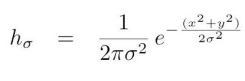

This is implemented in the code below:

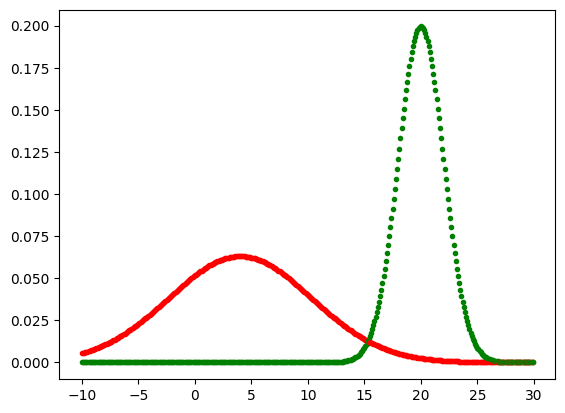

In [66]:
def f(u, sigma2, x):
    return 1/np.sqrt(2*np.pi*sigma2) * np.exp(-0.5* ((x-u)**2/sigma2))

u = 4        # Mean for the state prediction
v = 20       # Mean for the mesurement
sigma2 = 40  # Variance for the state prediction
r2 = 4       # Variance for the mesuremnt

for x in np.arange(-10, 30, 0.1):
    plt.plot(x, f(u, sigma2, x),'.r')
    plt.plot(x, f(v, r2, x),'.g')

# Exercise 2a
We have here plotted two distributions. The Kalman filter makes its measurement update by combining the information from these two gaussians. 

Plot the final Gaussian after the measurement update based on the two Gaussians plotted above. Use the following formulas to do so:

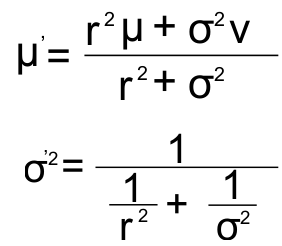

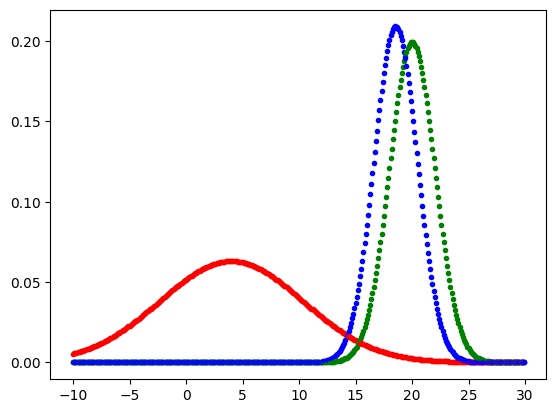

In [67]:
### Exercise 2a
### Compute and plot the Gaussian after measurement update
u_ = (r2 * u + sigma2 * v) / (r2 + sigma2)
sigma2_ = 1/((1/r2)+(1/sigma2))

for x in np.arange(-10, 30, 0.1):
    plt.plot(x, f(u, sigma2, x),'.r')
    plt.plot(x, f(v, r2, x),'.g')
    plt.plot(x, f(u_, sigma2_,x), '.b')

Notice that the resulting Gaussian has a higher peak than both of the others. This means that combining the two Gaussians we get a result that has less uncertainty than either of the original Gaussians.



 
 
 

### Extra: what the measurement update actually does

The update is **Bayes' rule**: posterior ∝ prior × likelihood. The plots below show this one step at a time:

1. **Multiply** the two curves point by point. The product is only large where *both* curves are large, so it is narrower than either one.
2. **Normalize** the product so its area is 1. The result is exactly the Gaussian from the formulas above.
3. **The weighting.** The new mean is `u + K·(v − u)`, where `K = σ² / (σ² + r²)` is the **Kalman gain**: the fraction of the way we move from the prediction to the measurement. A precise sensor (small r²) pulls the estimate almost all the way to the measurement. A noisy sensor barely moves it.

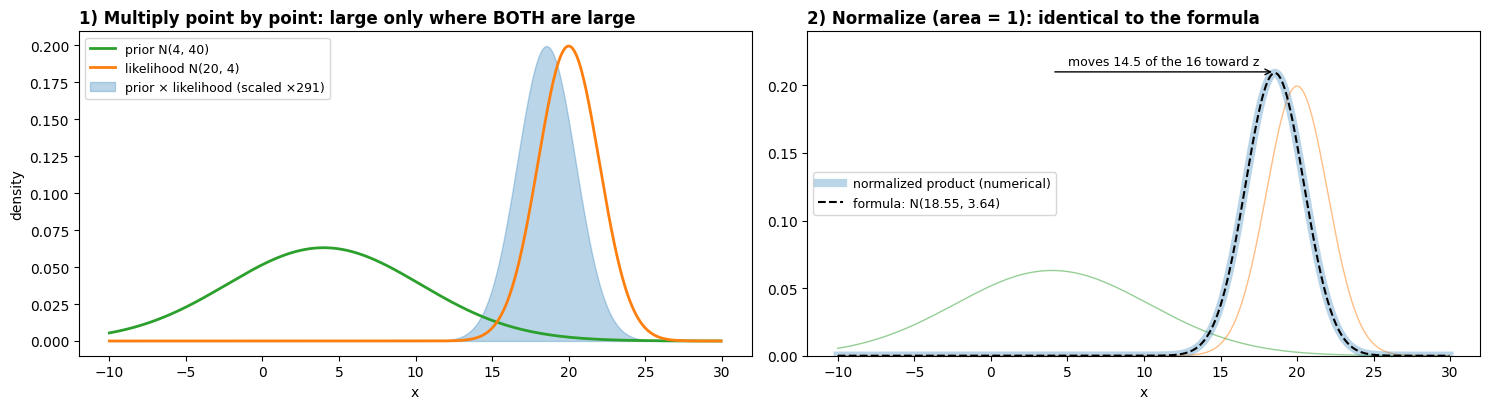

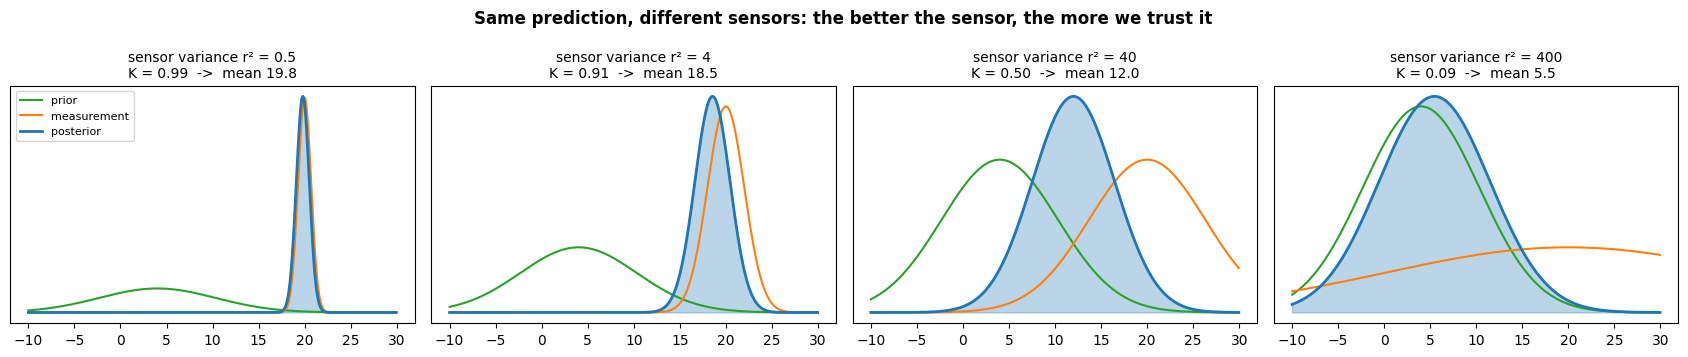

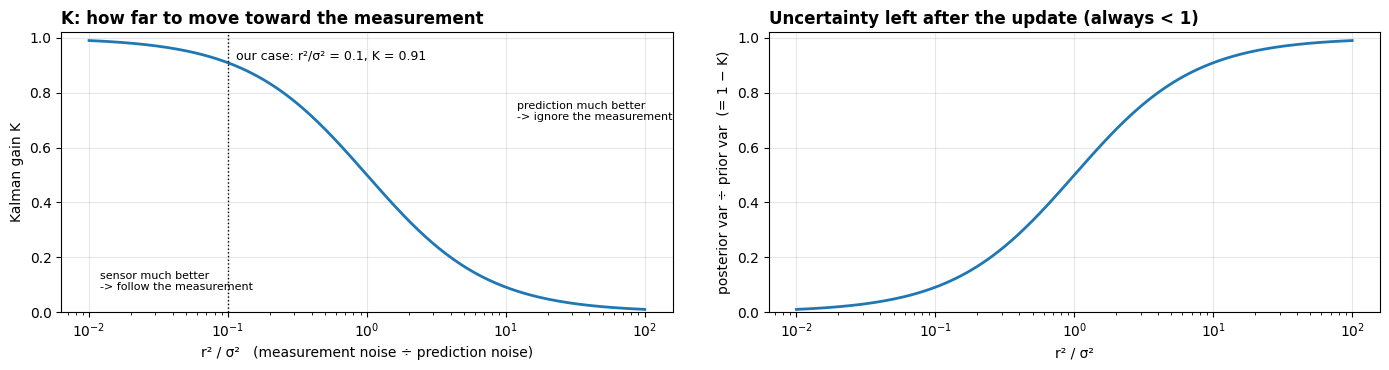

In [68]:
C_BELIEF, C_PRIOR, C_LIK, C_POST = "#9a9a9a", "#2ca02c", "#ff7f0e", "#1f77b4"

def update_1d(mu, var, z, var_z):
    # Same formulas as above: returns posterior mean and variance
    return (var_z * mu + var * z) / (var_z + var), 1 / (1 / var_z + 1 / var)

mu_p, var_p = 4, 40     # prior (prediction)
z, var_z = 20, 4        # measurement
grid = np.arange(-10, 30, 0.05)
prior, lik = f(mu_p, var_p, grid), f(z, var_z, grid)
product = prior * lik
mu_post, var_post = update_1d(mu_p, var_p, z, var_z)

# ---- Figure 1: multiply, then normalize ----
fig, axs = plt.subplots(1, 2, figsize=(15, 4.2))
ax = axs[0]
scale = lik.max() / product.max()          # the raw product is tiny, so scale it up to compare shapes
ax.plot(grid, prior, color=C_PRIOR, lw=2, label=f"prior N({mu_p}, {var_p})")
ax.plot(grid, lik, color=C_LIK, lw=2, label=f"likelihood N({z}, {var_z})")
ax.fill_between(grid, product * scale, color=C_POST, alpha=0.3,
                label=f"prior × likelihood (scaled ×{scale:.0f})")
ax.set_title("1) Multiply point by point: large only where BOTH are large", loc="left", fontweight="bold")
ax.set_xlabel("x"); ax.set_ylabel("density"); ax.legend(fontsize=9)

ax = axs[1]
area = np.trapezoid(product, grid) if hasattr(np, "trapezoid") else np.trapz(product, grid)
ax.plot(grid, prior, color=C_PRIOR, lw=1, alpha=0.5)
ax.plot(grid, lik, color=C_LIK, lw=1, alpha=0.5)
ax.plot(grid, product / area, color=C_POST, lw=6, alpha=0.3, label="normalized product (numerical)")
ax.plot(grid, f(mu_post, var_post, grid), "k--", lw=1.5,
        label=f"formula: N({mu_post:.2f}, {var_post:.2f})")
ax.annotate("", xy=(mu_post, 0.21), xytext=(mu_p, 0.21),
            arrowprops=dict(arrowstyle="->", color="k"))
ax.text((mu_p + mu_post) / 2, 0.215, f"moves {mu_post - mu_p:.1f} of the {z - mu_p} toward z",
        ha="center", fontsize=9)
ax.set_title("2) Normalize (area = 1): identical to the formula", loc="left", fontweight="bold")
ax.set_xlabel("x"); ax.set_ylim(0, 0.24); ax.legend(fontsize=9, loc="center left")
fig.tight_layout(); plt.show()

# ---- Figure 2: same prior, sensors of different quality ----
sensor_vars = [0.5, 4, 40, 400]
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6), sharex=True)
for ax, rv in zip(axs, sensor_vars):
    m, v = update_1d(mu_p, var_p, z, rv)
    K = var_p / (var_p + rv)
    ax.plot(grid, f(mu_p, var_p, grid), color=C_PRIOR, lw=1.5, label="prior")
    ax.plot(grid, f(z, rv, grid), color=C_LIK, lw=1.5, label="measurement")
    ax.fill_between(grid, f(m, v, grid), color=C_POST, alpha=0.3)
    ax.plot(grid, f(m, v, grid), color=C_POST, lw=2, label="posterior")
    ax.set_title(f"sensor variance r² = {rv}\nK = {K:.2f}  ->  mean {m:.1f}", fontsize=10)
    ax.set_yticks([])
axs[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Same prediction, different sensors: the better the sensor, the more we trust it",
             fontweight="bold")
fig.tight_layout(); plt.show()

# ---- Figure 3: Kalman gain as a function of how noisy the sensor is ----
ratio = np.logspace(-2, 2, 300)              # r² / σ²  (measurement noise relative to prior)
K = 1 / (1 + ratio)
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8))
axs[0].semilogx(ratio, K, color=C_POST, lw=2)
axs[0].axvline(var_z / var_p, color="k", ls=":", lw=1)
axs[0].text(var_z / var_p * 1.15, 0.92, f"our case: r²/σ² = {var_z/var_p:.1f}, K = {var_p/(var_p+var_z):.2f}", fontsize=9)
axs[0].set_xlabel("r² / σ²   (measurement noise ÷ prediction noise)")
axs[0].set_ylabel("Kalman gain K")
axs[0].set_title("K: how far to move toward the measurement", loc="left", fontweight="bold")
axs[0].text(0.012, 0.08, "sensor much better\n-> follow the measurement", fontsize=8)
axs[0].text(12, 0.7, "prediction much better\n-> ignore the measurement", fontsize=8)

axs[1].semilogx(ratio, 1 - K, color=C_POST, lw=2)   # posterior var / prior var = 1 - K
axs[1].set_xlabel("r² / σ²")
axs[1].set_ylabel("posterior var ÷ prior var  (= 1 − K)")
axs[1].set_title("Uncertainty left after the update (always < 1)", loc="left", fontweight="bold")
for ax in axs:
    ax.set_ylim(0, 1.02); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()






Next we have the prediction or motion update. This one is simply made by adding the motion to the Gaussian mean and the motion variance to the Gaussian variance:


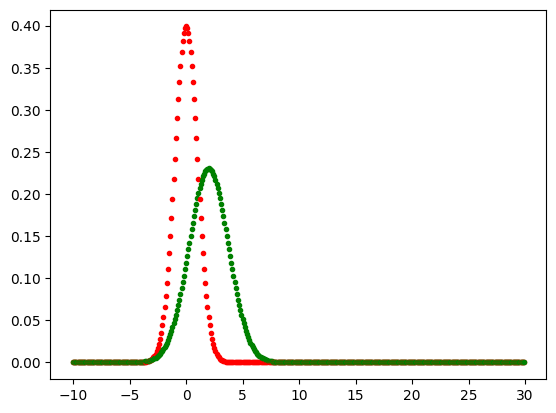

In [69]:
def predict(u1, s2_1, u2, s2_2):
    u = u1 + u2
    s2 = s2_1 + s2_2
    return [u, s2]

u = 0
s2 = 1

motion = 2
motion_sigma2 = 2

[u_pred, s2_pred] = predict(u, s2, motion, motion_sigma2)

for x in np.arange(-10, 30, 0.1):
    plt.plot(x, f(u, s2, x),'.r')
    plt.plot(x, f(u_pred, s2_pred, x),'.g')

# Exercise 2b
Combine the update function you made in the previous exercise with the predict function given above and plot all the Gaussians calculated using the measurements and motions given in the code below:

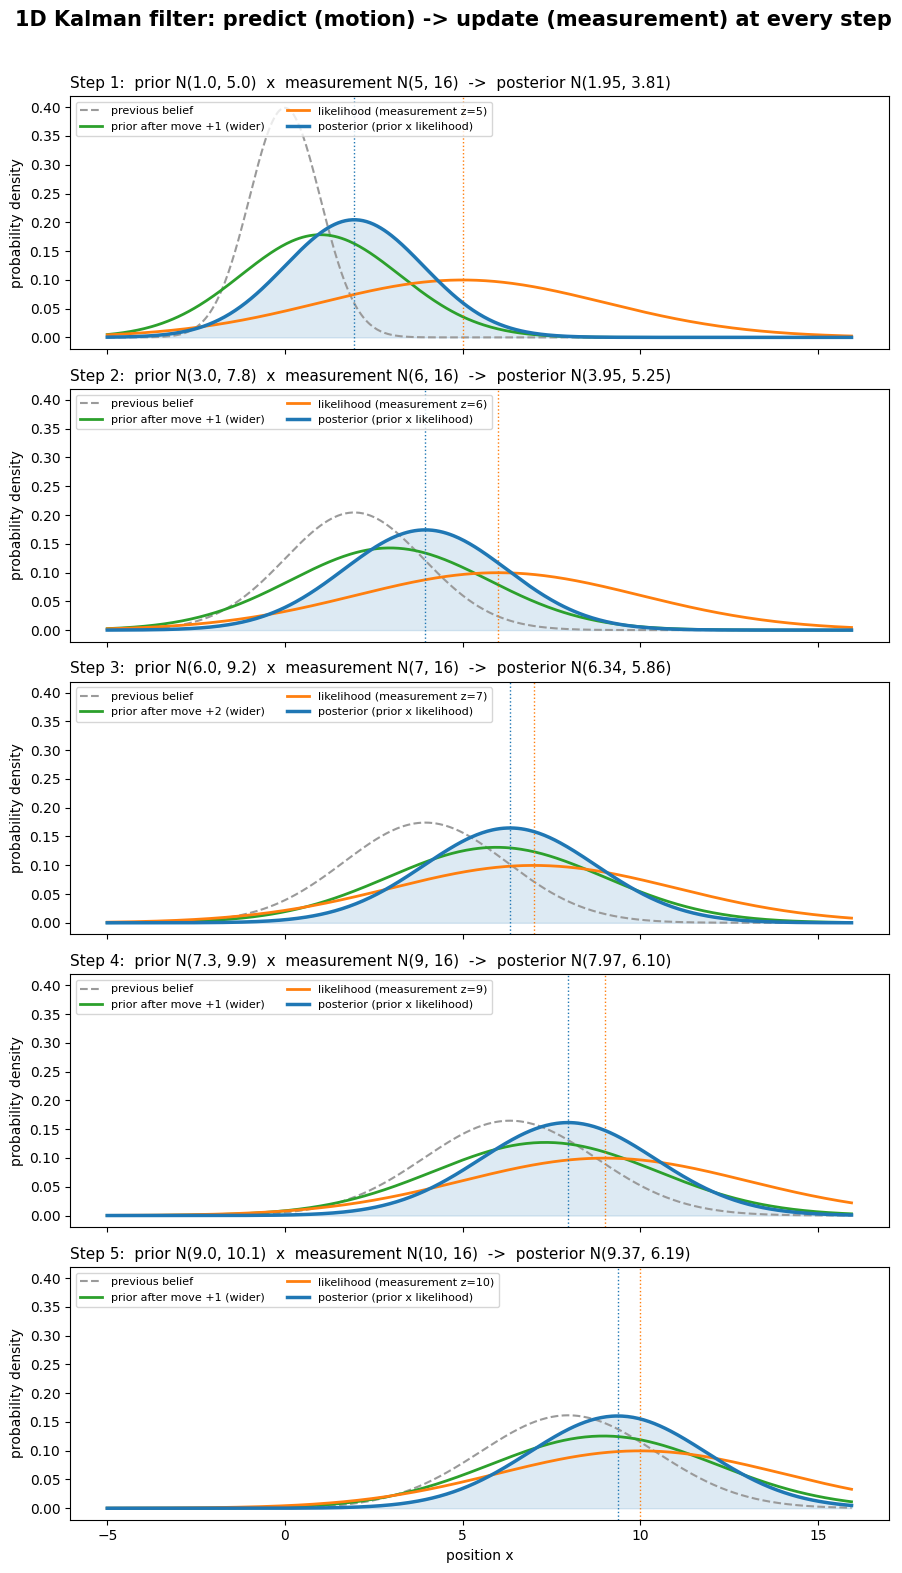

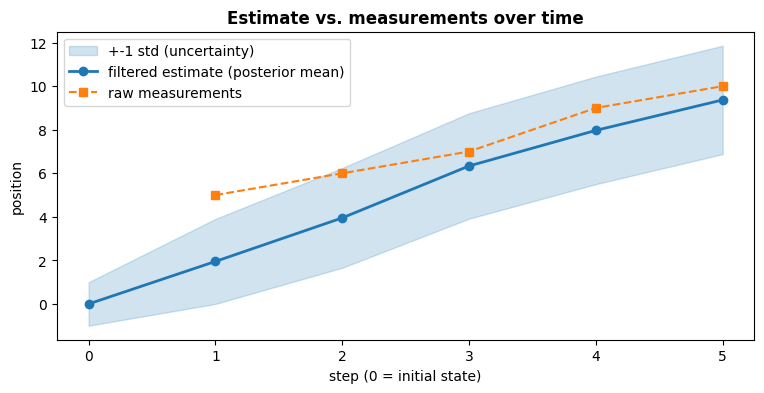

In [70]:
### Exercise 2b
measurements = [5, 6, 7, 9, 10]
measure_sigma = 4
measure_sigma2 = measure_sigma **2
motion = [1, 1, 2, 1, 1]
motion_sigma = 2
motion_sigma2 = motion_sigma ** 2

n = len(measurements)

def bayes(u, sigma2, v, r2):
    # Measurement update = Bayes' rule: posterior ~ prior * likelihood.
    # Multiplying two Gaussians gives a new Gaussian:
    #   mean     = weighted average, where the LESS uncertain one gets MORE weight
    #   variance = always smaller than both inputs (we gained information)
    u_ = (r2 * u + sigma2 * v) / (r2 + sigma2)
    sigma2_ = 1/((1/r2)+(1/sigma2))
    return u_, sigma2_

# ---------------------------------------------------------------------------
# Each row below is one cycle of the Kalman filter. It has 4 curves:
#   belief (red)       : what we believed at the END of the last cycle (the last posterior)
#   prior (green)      : belief after PREDICT (motion). Mean moves, variance GROWS
#   likelihood (orange): the measurement, N(z, measure_sigma2). What the sensor says
#   posterior (blue)   : after UPDATE = prior x likelihood (Bayes). Variance SHRINKS
# ---------------------------------------------------------------------------
C_BELIEF, C_PRIOR, C_LIK, C_POST = "#9a9a9a", "#2ca02c", "#ff7f0e", "#1f77b4"

xs = np.arange(-5, 16, 0.05)          # x-axis grid (positions) for all curves
fig, axs = plt.subplots(n, 1, figsize=(9, 3.2 * n), sharex=True, sharey=True)
fig.suptitle("1D Kalman filter: predict (motion) -> update (measurement) at every step",
             fontsize=15, fontweight="bold")

# initialize state: start at position 0 with variance 1
u, s2 = 0, 1
history = [(u, s2)]                   # posterior (mean, variance) after each step, for the summary plot

for i in range(n):
    ax = axs[i]

    # 1) Belief from last step (becomes the starting point of this step)
    u_old, s2_old = u, s2
    ax.plot(xs, f(u_old, s2_old, xs), color=C_BELIEF, ls="--", lw=1.5,
            label="previous belief")

    # 2) PREDICT: add the motion to the mean, add motion noise to the variance.
    #    This gives the PRIOR for this measurement: we know less than before.
    u, s2 = predict(u, s2, motion[i], motion_sigma2)
    u_prior, s2_prior = u, s2
    ax.plot(xs, f(u_prior, s2_prior, xs), color=C_PRIOR, lw=2,
            label=f"prior after move +{motion[i]} (wider)")

    # 3) MEASUREMENT: the sensor gives z, but with noise -> a Gaussian around z.
    #    This is the LIKELIHOOD: how plausible each position is given the reading.
    z = measurements[i]
    ax.plot(xs, f(z, measure_sigma2, xs), color=C_LIK, lw=2,
            label=f"likelihood (measurement z={z})")
    ax.axvline(z, color=C_LIK, ls=":", lw=1)

    # 4) UPDATE (Bayes): posterior = prior x likelihood, normalized.
    #    Lies between prior and measurement, and is narrower than both.
    u, s2 = bayes(u_prior, s2_prior, z, measure_sigma2)
    post = f(u, s2, xs)
    ax.plot(xs, post, color=C_POST, lw=2.5, label="posterior (prior x likelihood)")
    ax.fill_between(xs, post, color=C_POST, alpha=0.15)
    ax.axvline(u, color=C_POST, ls=":", lw=1)
    history.append((u, s2))

    ax.set_title(f"Step {i+1}:  prior N({u_prior:.1f}, {s2_prior:.1f})  x  "
                 f"measurement N({z}, {measure_sigma2})  ->  "
                 f"posterior N({u:.2f}, {s2:.2f})", fontsize=11, loc="left")
    ax.set_ylabel("probability density")
    ax.legend(loc="upper left", fontsize=8, ncol=2)

axs[-1].set_xlabel("position x")
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# ---------------------------------------------------------------------------
# Summary: how the estimate evolves over time compared with the raw measurements.
# The band is +-1 standard deviation. It shrinks quickly, then stays roughly constant
# because each predict step adds uncertainty and each update step removes some.
# ---------------------------------------------------------------------------
means = np.array([h[0] for h in history])
stds = np.sqrt([h[1] for h in history])
t = np.arange(len(means))

plt.figure(figsize=(9, 4))
plt.fill_between(t, means - stds, means + stds, color=C_POST, alpha=0.2, label="+-1 std (uncertainty)")
plt.plot(t, means, "o-", color=C_POST, lw=2, label="filtered estimate (posterior mean)")
plt.plot(t[1:], measurements, "s--", color=C_LIK, label="raw measurements")
plt.title("Estimate vs. measurements over time", fontweight="bold")
plt.xlabel("step (0 = initial state)")
plt.ylabel("position")
plt.legend()
plt.show()


### Extra: the rhythm of the filter (2b)

- **Left:** variance over time. Every **predict** adds the motion noise (up). Every **update** removes some uncertainty (down). After a few steps the two balance out, and the variance settles into a steady sawtooth.
- **Right:** where the estimate lands at each step. The posterior (blue) always lies on the line between the prediction (green) and the measurement (orange). The Kalman gain K sets how far along that line it lands.

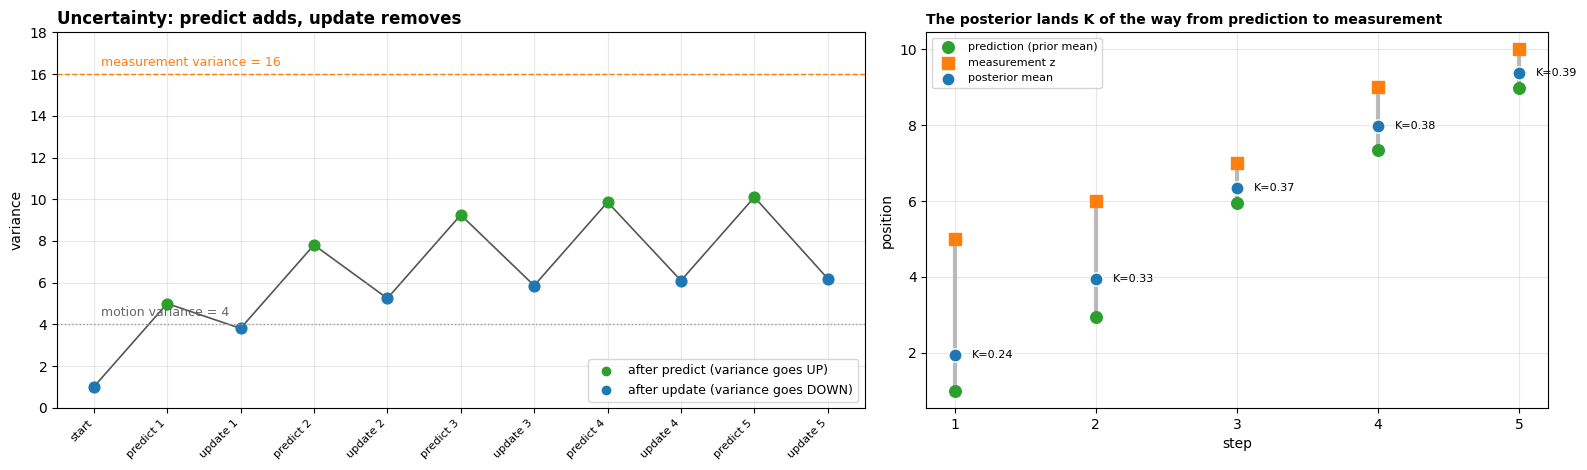

In [71]:
u_k, s2_k = 0, 1
labels_t, var_t, kind_t = ["start"], [s2_k], ["post"]
rows = []                                     # (prior mean, z, posterior mean, K) per step
for i in range(n):
    mu_prior, s2_prior = predict(u_k, s2_k, motion[i], motion_sigma2)
    K = s2_prior / (s2_prior + measure_sigma2)
    u_k, s2_k = bayes(mu_prior, s2_prior, measurements[i], measure_sigma2)
    labels_t += [f"predict {i+1}", f"update {i+1}"]
    var_t += [s2_prior, s2_k]
    kind_t += ["prior", "post"]
    rows.append((mu_prior, measurements[i], u_k, K))

fig, axs = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})

# ---- Left: variance sawtooth ----
ax = axs[0]
t = np.arange(len(var_t))
ax.plot(t, var_t, color="#555", lw=1.2, zorder=1)
for tt, vv, kk in zip(t, var_t, kind_t):
    ax.scatter(tt, vv, s=60, zorder=2, color=C_PRIOR if kk == "prior" else C_POST)
ax.axhline(measure_sigma2, color=C_LIK, ls="--", lw=1)
ax.text(0.1, measure_sigma2 + 0.4, f"measurement variance = {measure_sigma2}", color=C_LIK, fontsize=9)
ax.axhline(motion_sigma2, color=C_BELIEF, ls=":", lw=1)
ax.text(0.1, motion_sigma2 + 0.4, f"motion variance = {motion_sigma2}", color="#666", fontsize=9)
ax.scatter([], [], color=C_PRIOR, label="after predict (variance goes UP)")
ax.scatter([], [], color=C_POST, label="after update (variance goes DOWN)")
ax.set_xticks(t, labels_t, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("variance")
ax.set_title("Uncertainty: predict adds, update removes", loc="left", fontweight="bold")
ax.set_ylim(0, 18)
ax.legend(fontsize=9, loc="lower right"); ax.grid(alpha=0.3)

# ---- Right: prediction vs measurement vs result ----
ax = axs[1]
for i, (mp, zz, mpost, K) in enumerate(rows):
    s = i + 1
    ax.plot([s, s], [mp, zz], color="#bbb", lw=3, zorder=1)
    ax.scatter(s, mp, color=C_PRIOR, s=70, zorder=2, label="prediction (prior mean)" if i == 0 else None)
    ax.scatter(s, zz, color=C_LIK, marker="s", s=70, zorder=2, label="measurement z" if i == 0 else None)
    ax.scatter(s, mpost, color=C_POST, s=90, zorder=3, edgecolor="white", label="posterior mean" if i == 0 else None)
    ax.text(s + 0.12, mpost, f"K={K:.2f}", fontsize=8, va="center")
ax.set_xlabel("step"); ax.set_ylabel("position")
ax.set_xticks(range(1, n + 1))
ax.set_title("The posterior lands K of the way from prediction to measurement",
             loc="left", fontweight="bold", fontsize=10)
ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

# Exercise 2c

It's now time to look at the more general equations of the Kalman filter. We would like to apply a Kalman filter for a robot moving in 1D. We would like to track and predict its position and its velocity. 

A quick summary of the variables:

**x** : The state matrix. Holds the state of the robot, which is its position and velocity.

**P** : The uncertainty of the state.

**u** : The external motion. In this case there will not be an external motion affecting the robot.

**F** : The transition matrix (or next state function). Used to predict the next state of the robot.

**H** : The observation matrix (or measurement function). Used to update the robot state.

**R** : The measurement uncertainty. 

**I** : Identity matrix.

You will now have to implement your own update and predict function using the formulas given here. All the matrices are given in the code below. 

When you multiply matrices together you can use [np.dot](https://docs.scipy.org/doc/numpy/reference/generated/numpy.dot.html). To get the inverse of a matrix, you can use [np.linalg.pinv](https://docs.scipy.org/doc/numpy/reference/generated/numpy.linalg.pinv.html). To get the transpose you can use [np.transpose](https://docs.scipy.org/doc/numpy/reference/generated/numpy.transpose.html).

The two equations written in black are the equations used for prediction and the rest are the equations used for updating.

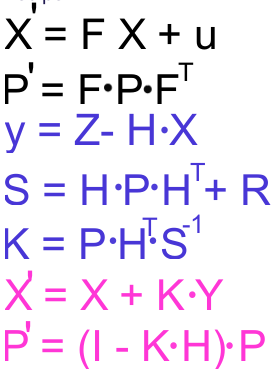

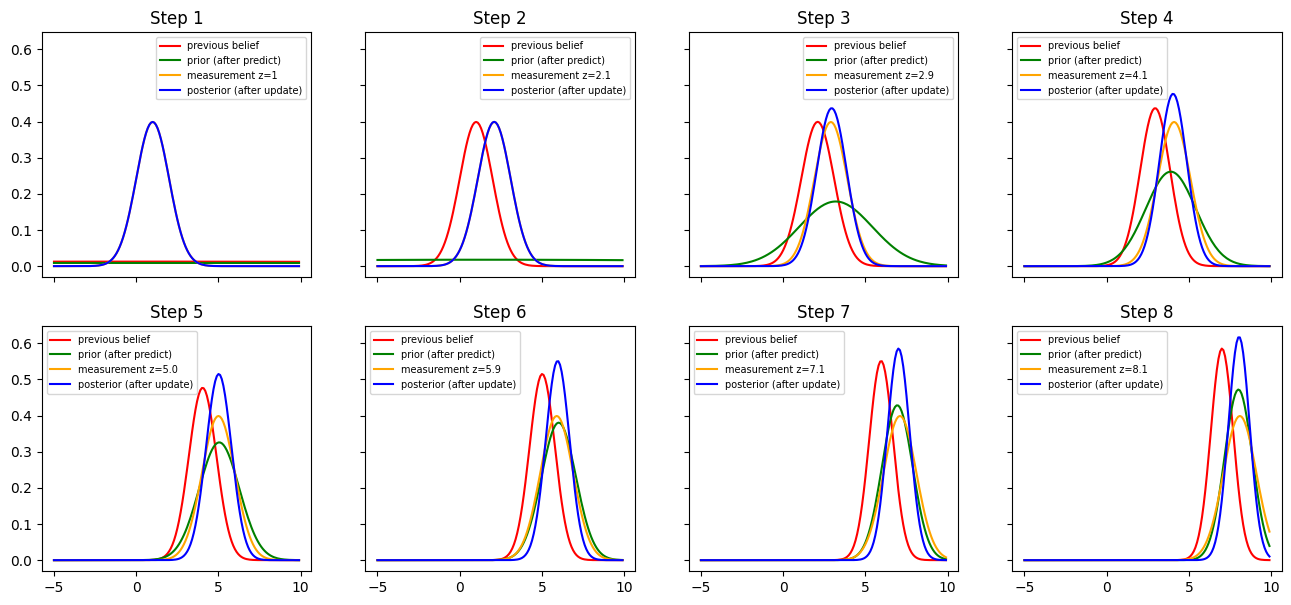

In [72]:
# The initial state. The robot starts in position 0 with the velocity 0.
x = np.array([[0],
              [0]])
# The initial uncertainty. We start with some very large values.
P = np.array([[1000, 0],
              [0, 1000]])
# The external motion. Set to 0 here.
u = np.array([[0],
              [0]])
# The transition matrix. 
F = np.array([[1, 1],
              [0, 1]])
# The observation matrix. We only get the position as measurement.
H = np.array([[1, 0]])
# The measurement uncertainty
R = 1

# The identity matrix. Simply a matrix with 1 in the diagonal and 0 elsewhere.
I = np.array([[1, 0],
              [0, 1]])

# The measured position. The robot move 1 every time, but due to sensor uncertainties, we measure a bit off.
measurements = [1, 2.1, 2.9, 4.1, 5.0, 5.9, 7.1, 8.1]

def update(x, P, Z, H, R, I):
    ### Insert update function
    y = Z - np.dot(H, x)
    S = np.dot(np.dot(H, P), np.transpose(H)) + R
    K = np.dot(np.dot(P, np.transpose(H)), np.linalg.pinv(S))
    #print(K)

    x_ = x + np.dot(K, y)
    P_ = np.dot((I - np.dot(K, H)), P)

    return x_, P_
    
def predict(x, P, F, u):
    ### insert predict function
    x_ = np.dot(F, x) + u
    P_ = np.dot(np.dot(F, P), np.transpose(F))
    return x_, P_


### Loop through the measurements ###
u = np.array([0,0])

### Loop through the measurements ###
n = len(measurements)
xs = np.arange(-5, 10, 0.1)               # positions to evaluate the Gaussians at
fig, axs = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey=True)
axs = axs.ravel()                           # flatten 2x4 grid so axs[i] works

for i, z in enumerate(measurements):
    # Belief before this step (position part of the state: mean x[0,0], variance P[0,0])
    axs[i].plot(xs, f(x[0,0], P[0, 0], xs), 'r', label='previous belief')

    # PREDICT: use F (position += velocity) and the external motion u (zero here)
    x, P = predict(x, P, F, u)
    axs[i].plot(xs, f(x[0,0], P[0, 0], xs), 'g', label='prior (after predict)')

    # MEASUREMENT: only the position is measured, noise variance R
    axs[i].plot(xs, f(z, R, xs), color='orange', label=f'measurement z={z}')

    # UPDATE: combine prior and measurement (Bayes)
    x, P = update(x, P, z, H, R, I)
    axs[i].plot(xs, f(x[0,0], P[0, 0], xs), '-b', label='posterior (after update)')

    axs[i].set_title(f'Step {i + 1}')
    axs[i].legend(fontsize=7)

plt.show()

Notice how the uncertainty **P** gets smaller and the predicted states gets more accurate than the actual measurements.

### Extra: what happens inside the 2D state (position + velocity)

The sensor only measures **position**, yet the filter ends up confident about **velocity** too. The plots below show how.

1. **Estimates over time.** The velocity estimate converges to the true value of 1 even though velocity is never measured.
2. **Kalman gain K = [K_pos, K_vel].** This is how much each part of the state is corrected by the position error y. At first the gains are large (we trust the measurements). Later they shrink, because the prediction is now good.
3. **The covariance as an ellipse in (position, velocity) space.** This is the key picture.
   - **Predict** (`F P Fᵀ`) *shears* the ellipse. If the velocity is higher, the robot ends up further ahead, so position and velocity become **correlated** (the ellipse tilts).
   - The **measurement** only says "position is about z", which is a vertical band with any velocity allowed.
   - The **update** keeps the part of the tilted ellipse that lies inside the band. Because the ellipse is tilted, fixing the position also fixes the velocity.

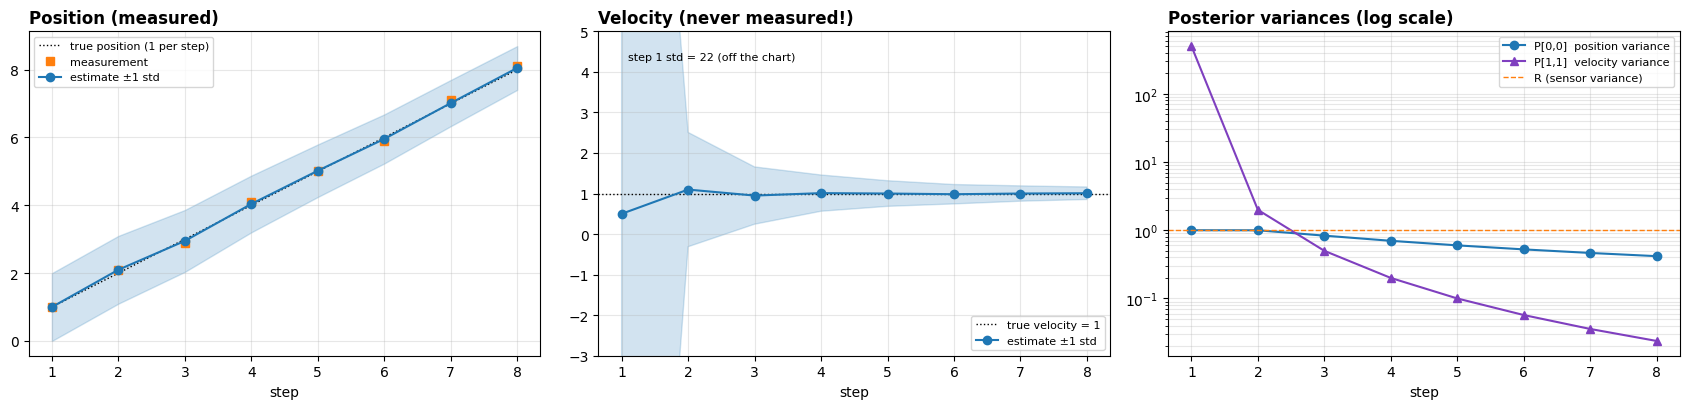

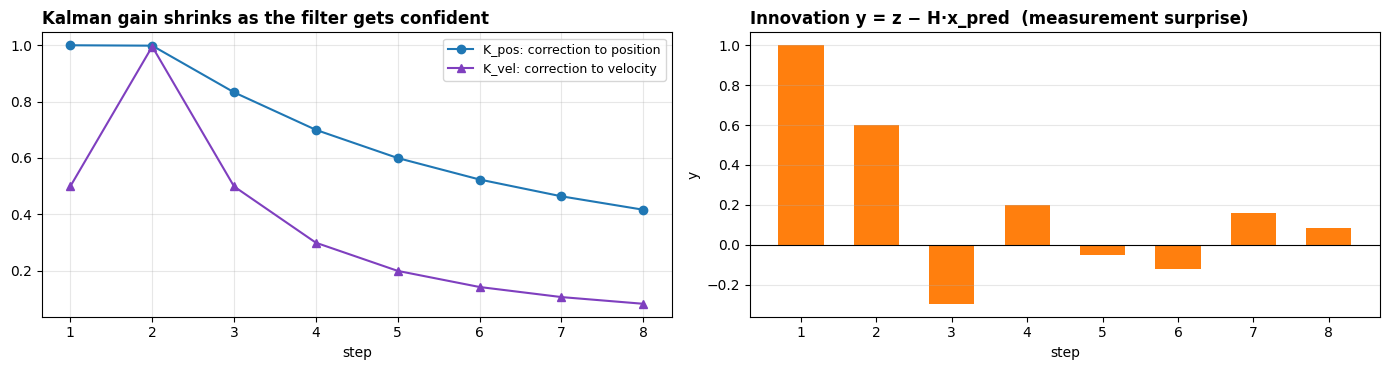

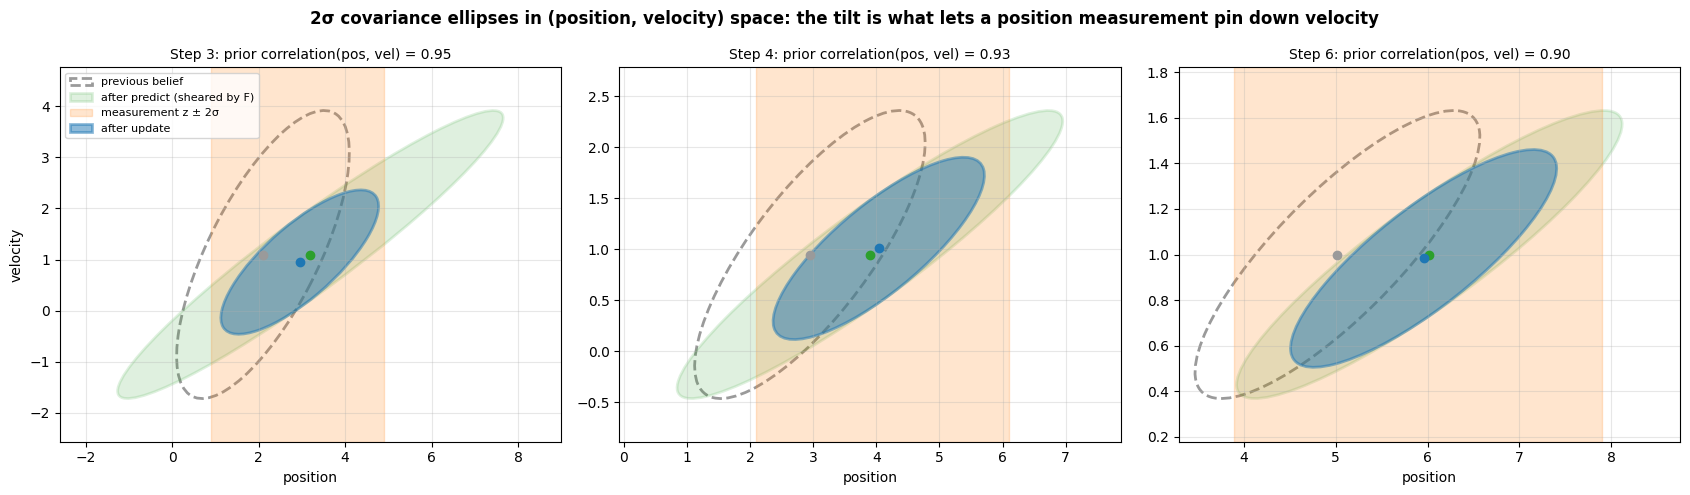

In [73]:
from matplotlib.patches import Ellipse

def cov_ellipse(ax, mean, cov, nstd=2, **kw):
    # Draw the nstd-sigma ellipse of a 2D Gaussian
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    w, h = 2 * nstd * np.sqrt(vals[::-1])
    ax.add_patch(Ellipse(mean, w, h, angle=angle, **kw))

# Re-run the 1D-robot filter and keep everything for plotting
F2 = np.array([[1., 1.], [0., 1.]]); H2 = np.array([[1., 0.]]); I2 = np.eye(2); R2 = 1.
x_k, P_k = np.zeros((2, 1)), np.diag([1000., 1000.])
u_k = np.zeros((2, 1))
hist = []          # dict per step
for z in measurements:
    x_prev, P_prev = x_k, P_k
    x_pr, P_pr = predict(x_k, P_k, F2, u_k)
    S = H2 @ P_pr @ H2.T + R2
    K = P_pr @ H2.T @ np.linalg.pinv(S)
    x_k, P_k = update(x_pr, P_pr, z, H2, R2, I2)
    hist.append(dict(x_prev=x_prev, P_prev=P_prev, x_pr=x_pr, P_pr=P_pr, x=x_k, P=P_k, K=K, z=z))

steps = np.arange(1, len(measurements) + 1)
pos = np.array([h["x"][0, 0] for h in hist]); vel = np.array([h["x"][1, 0] for h in hist])
pos_sd = np.sqrt([h["P"][0, 0] for h in hist]); vel_sd = np.sqrt([h["P"][1, 1] for h in hist])

# ---- Figure 1: estimates with ±1 std bands, plus the variances on a log scale ----
fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
ax = axs[0]
ax.plot(steps, steps, color="k", ls=":", lw=1, label="true position (1 per step)")
ax.plot(steps, measurements, "s", color=C_LIK, label="measurement")
ax.fill_between(steps, pos - pos_sd, pos + pos_sd, color=C_POST, alpha=0.2)
ax.plot(steps, pos, "o-", color=C_POST, label="estimate ±1 std")
ax.set_title("Position (measured)", loc="left", fontweight="bold")
ax.set_xlabel("step"); ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axs[1]
ax.axhline(1, color="k", ls=":", lw=1, label="true velocity = 1")
ax.fill_between(steps, vel - vel_sd, vel + vel_sd, color=C_POST, alpha=0.2)
ax.plot(steps, vel, "o-", color=C_POST, label="estimate ±1 std")
ax.set_ylim(-3, 5)
ax.text(1.1, 4.3, f"step 1 std = {vel_sd[0]:.0f} (off the chart)", fontsize=8)
ax.set_title("Velocity (never measured!)", loc="left", fontweight="bold")
ax.set_xlabel("step"); ax.legend(fontsize=8, loc="lower right"); ax.grid(alpha=0.3)

ax = axs[2]
ax.semilogy(steps, pos_sd ** 2, "o-", color=C_POST, label="P[0,0]  position variance")
ax.semilogy(steps, vel_sd ** 2, "^-", color="#7f3fbf", label="P[1,1]  velocity variance")
ax.axhline(R2, color=C_LIK, ls="--", lw=1, label="R (sensor variance)")
ax.set_title("Posterior variances (log scale)", loc="left", fontweight="bold")
ax.set_xlabel("step"); ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
fig.tight_layout(); plt.show()

# ---- Figure 2: Kalman gain and the innovation ----
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8))
Kp = [h["K"][0, 0] for h in hist]; Kv = [h["K"][1, 0] for h in hist]
axs[0].plot(steps, Kp, "o-", color=C_POST, label="K_pos: correction to position")
axs[0].plot(steps, Kv, "^-", color="#7f3fbf", label="K_vel: correction to velocity")
axs[0].set_title("Kalman gain shrinks as the filter gets confident", loc="left", fontweight="bold")
axs[0].set_xlabel("step"); axs[0].legend(fontsize=9); axs[0].grid(alpha=0.3)

y_inn = [h["z"] - h["x_pr"][0, 0] for h in hist]
axs[1].bar(steps, y_inn, color=C_LIK, width=0.6)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_title("Innovation y = z − H·x_pred  (measurement surprise)", loc="left", fontweight="bold")
axs[1].set_xlabel("step"); axs[1].set_ylabel("y"); axs[1].grid(alpha=0.3, axis="y")
fig.tight_layout(); plt.show()

# ---- Figure 3: the covariance ellipse through one predict + update cycle ----
show = [2, 3, 5]          # 0-based step indices to show (steps 3, 4, 6)
fig, axs = plt.subplots(1, len(show), figsize=(17, 5))
for ax, k in zip(axs, show):
    h = hist[k]
    cov_ellipse(ax, h["x_prev"][:, 0], h["P_prev"], fc="none", ec=C_BELIEF, lw=2, ls="--",
                label="previous belief")
    cov_ellipse(ax, h["x_pr"][:, 0], h["P_pr"], fc=C_PRIOR, alpha=0.15, ec=C_PRIOR, lw=2,
                label="after predict (sheared by F)")
    zsd = 2 * np.sqrt(R2)
    ax.axvspan(h["z"] - zsd, h["z"] + zsd, color=C_LIK, alpha=0.2, label="measurement z ± 2σ")
    cov_ellipse(ax, h["x"][:, 0], h["P"], fc=C_POST, alpha=0.5, ec=C_POST, lw=2,
                label="after update")
    for key, c in [("x_prev", C_BELIEF), ("x_pr", C_PRIOR), ("x", C_POST)]:
        ax.plot(*h[key][:, 0], "o", color=c, ms=6)
    # axis range from the prior ellipse
    sd = np.sqrt(np.diag(h["P_pr"])); m = h["x_pr"][:, 0]
    ax.set_xlim(m[0] - 2.6 * sd[0], m[0] + 2.6 * sd[0])
    ax.set_ylim(m[1] - 2.6 * sd[1], m[1] + 2.6 * sd[1])
    corr = h["P_pr"][0, 1] / np.prod(sd)
    ax.set_title(f"Step {k+1}: prior correlation(pos, vel) = {corr:.2f}", fontsize=10)
    ax.set_xlabel("position"); ax.grid(alpha=0.3)
axs[0].set_ylabel("velocity")
axs[0].legend(fontsize=8, loc="upper left")
fig.suptitle("2σ covariance ellipses in (position, velocity) space: the tilt is what lets a position "
             "measurement pin down velocity", fontweight="bold")
fig.tight_layout(); plt.show()

# Exercise 2d
Extent the previous matrices such that the robot can move in 2D. The update and predict functions don't have to be changed, only the matrices. For example the state matrix will now have to hold both the position and velocity in both the x- and y-direction: 


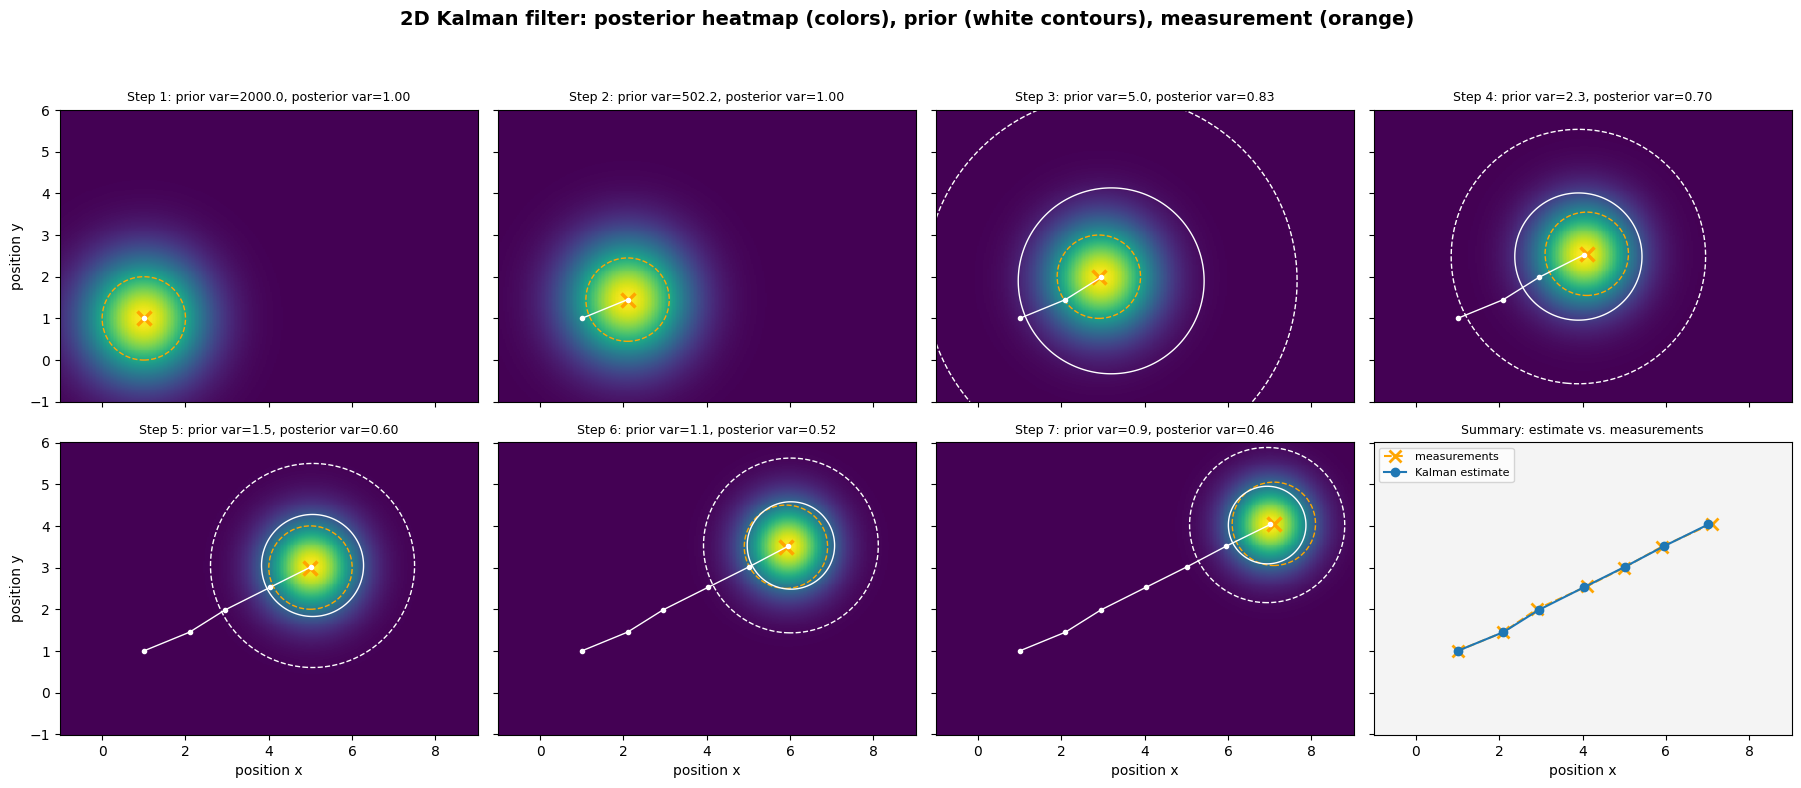

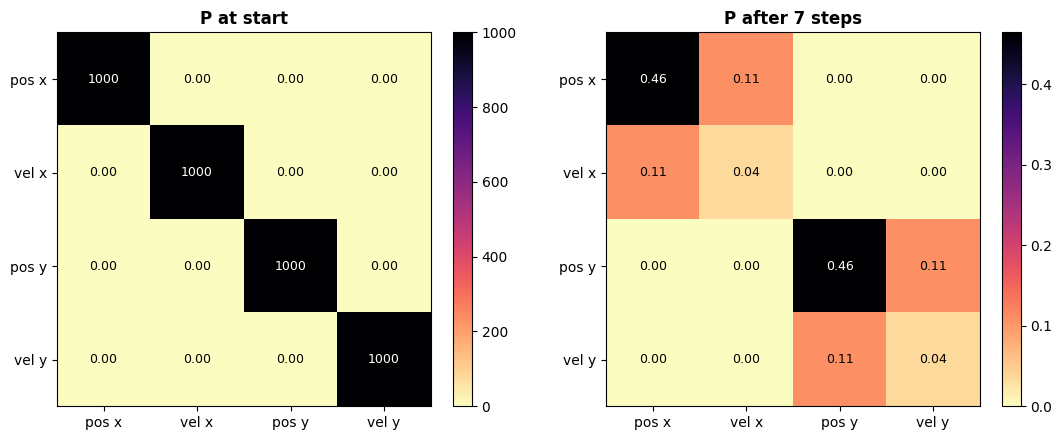

Final state [pos x, vel x, pos y, vel y]: [7.014 1.    4.034 0.509]


In [74]:
# The initial state. The robot starts in position 0 with the velocity 0.
x = np.array([[0], # Position along the x-axis
              [0], # Velocity along the x-axis
              [0], # Position along the y-axis
              [0]])# Velocity along the y-axis

### Update the rest of the parameters 
F = np.array([[1, 1, 0, 0],
              [0, 1, 0, 0],
              [0, 0, 1, 1],
              [0, 0, 0, 1]])
H = np.array([[1, 0, 0, 0],
              [0, 0, 1, 0]])
P = np.array([[1000, 0, 0, 0],
              [0, 1000, 0, 0],
              [0, 0, 1000, 0],
              [0, 0, 0, 1000]])
R = np.eye(2)
I = np.eye(4)
# You can use the following measurements or come up with your own. 
measurements_x = [1, 2.1, 2.9, 4.1, 5.0, 5.9, 7.1]
measurements_y = [1, 1.45, 2.0, 2.55, 3, 3.5, 4.05]
u = np.zeros_like(x)

# ---------------------------------------------------------------------------
# The belief about the POSITION is a 2D Gaussian:
#   mean       = (x[0], x[2])                      -> pos_x, pos_y from the state
#   covariance = [[P[0,0], P[0,2]], [P[2,0], P[2,2]]] -> rows/cols for pos_x, pos_y
# That is what the heatmaps below show (velocity is still in the state, just not drawn).
# ---------------------------------------------------------------------------
POS = [0, 2]                                  # indices of pos_x and pos_y in the state

def pos_gaussian(x, P):
    """Mean (2,) and covariance (2,2) of the position part of the state."""
    return x[POS, 0], P[np.ix_(POS, POS)]

def gauss2d(mean, cov, X, Y):
    """2D Gaussian density on a grid (the 2D version of f from earlier)."""
    d = np.stack([X - mean[0], Y - mean[1]], axis=-1)
    inv = np.linalg.inv(cov)
    expo = np.einsum('...i,ij,...j->...', d, inv, d)
    return np.exp(-0.5 * expo) / (2 * np.pi * np.sqrt(np.linalg.det(cov)))

# Run the filter and remember prior (after predict) and posterior (after update)
priors, posteriors = [], []
for i in range(len(measurements_x)):
    z = np.array([[measurements_x[i]],
                  [measurements_y[i]]])
    x, P = predict(x, P, F, u)                # PREDICT -> prior: moves and gets wider
    priors.append(pos_gaussian(x, P))
    x, P = update(x, P, z, H, R, I)           # UPDATE (Bayes) -> posterior: gets narrower
    posteriors.append(pos_gaussian(x, P))

# ---------------------------------------------------------------------------
# Plot 1: one heatmap per step.
#   colors (heatmap)  = posterior density (where the robot probably is AFTER the update)
#   white contours    = prior (prediction before the measurement), 1 and 2 std
#   orange x          = measurement z, dashed orange circle = 1 std of sensor noise (R)
#   white line        = path of posterior means so far
# ---------------------------------------------------------------------------
gx, gy = np.meshgrid(np.linspace(-1, 9, 300), np.linspace(-1, 6, 300))
n = len(measurements_x)
fig, axs = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
axs = axs.ravel()

for i in range(n):
    ax = axs[i]
    m_post, c_post = posteriors[i]
    m_prior, c_prior = priors[i]

    # Posterior heatmap (each panel scaled to its own max, so the shape is visible)
    post = gauss2d(m_post, c_post, gx, gy)
    ax.pcolormesh(gx, gy, post / post.max(), cmap='viridis', shading='auto', vmin=0, vmax=1)

    # Prior as contours at 1 and 2 std (Mahalanobis distance 1 and 2)
    prior = gauss2d(m_prior, c_prior, gx, gy)
    levels = prior.max() * np.exp(-0.5 * np.array([4, 1]))
    if np.isfinite(levels).all() and levels[0] < levels[1]:
        ax.contour(gx, gy, prior, levels=levels, colors='white', linewidths=1, linestyles=['--', '-'])

    # Measurement and its noise (R = identity -> circle with radius 1)
    zx, zy = measurements_x[i], measurements_y[i]
    ax.plot(zx, zy, 'x', color='orange', ms=10, mew=2.5)
    ax.add_patch(plt.Circle((zx, zy), np.sqrt(R[0, 0]), fill=False, color='orange', ls='--'))

    # Path of the estimate so far
    path = np.array([p[0] for p in posteriors[:i + 1]])
    ax.plot(path[:, 0], path[:, 1], 'w.-', lw=1)

    ax.set_title(f'Step {i+1}: prior var={c_prior[0,0]:.1f}, posterior var={c_post[0,0]:.2f}',
                 fontsize=9)
    ax.set_aspect('equal')

# Last panel: summary of the whole run
ax = axs[-1]
ax.set_facecolor('#f4f4f4')
path = np.array([p[0] for p in posteriors])
ax.plot(measurements_x, measurements_y, 'x--', color='orange', ms=8, mew=2, label='measurements')
ax.plot(path[:, 0], path[:, 1], 'o-', color='#1f77b4', label='Kalman estimate')
ax.set_title('Summary: estimate vs. measurements', fontsize=9)
ax.legend(fontsize=8, loc='upper left')
ax.set_aspect('equal')

for ax in axs[4:]:
    ax.set_xlabel('position x')
for ax in axs[::4]:
    ax.set_ylabel('position y')
fig.suptitle('2D Kalman filter: posterior heatmap (colors), prior (white contours), measurement (orange)',
             fontsize=14, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# ---------------------------------------------------------------------------
# Plot 2: the full 4x4 covariance matrix P as a heatmap, before and after.
# Diagonal = variance of each state variable, off-diagonal = how they are correlated.
# Note: velocity is never measured, but its variance still drops, because the filter
# infers velocity from how the position changes between measurements.
# ---------------------------------------------------------------------------
labels = ['pos x', 'vel x', 'pos y', 'vel y']
P0 = np.diag([1000, 1000, 1000, 1000])
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, M, title in [(axs[0], P0, 'P at start'), (axs[1], P, f'P after {n} steps')]:
    im = ax.imshow(M, cmap='magma_r')
    for r in range(4):
        for c in range(4):
            ax.text(c, r, f'{M[r, c]:.2f}' if abs(M[r, c]) < 100 else f'{M[r, c]:.0f}',
                    ha='center', va='center', fontsize=9,
                    color='white' if M[r, c] > M.max() / 2 else 'black')
    ax.set_xticks(range(4), labels)
    ax.set_yticks(range(4), labels)
    ax.set_title(title, fontweight='bold')
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

print('Final state [pos x, vel x, pos y, vel y]:', np.round(x.ravel(), 3))


### Extra: overview of the 2D run

- **Left:** the 1σ uncertainty ellipse of the position at every step, drawn on the same map. Green is after predict and blue is after update. The ellipses shrink quickly and then stay about the same size.
- **Right:** the two velocity estimates over time. Neither is measured, but both converge: about 1.0 in x and 0.5 in y, which is the slope of the measured path.

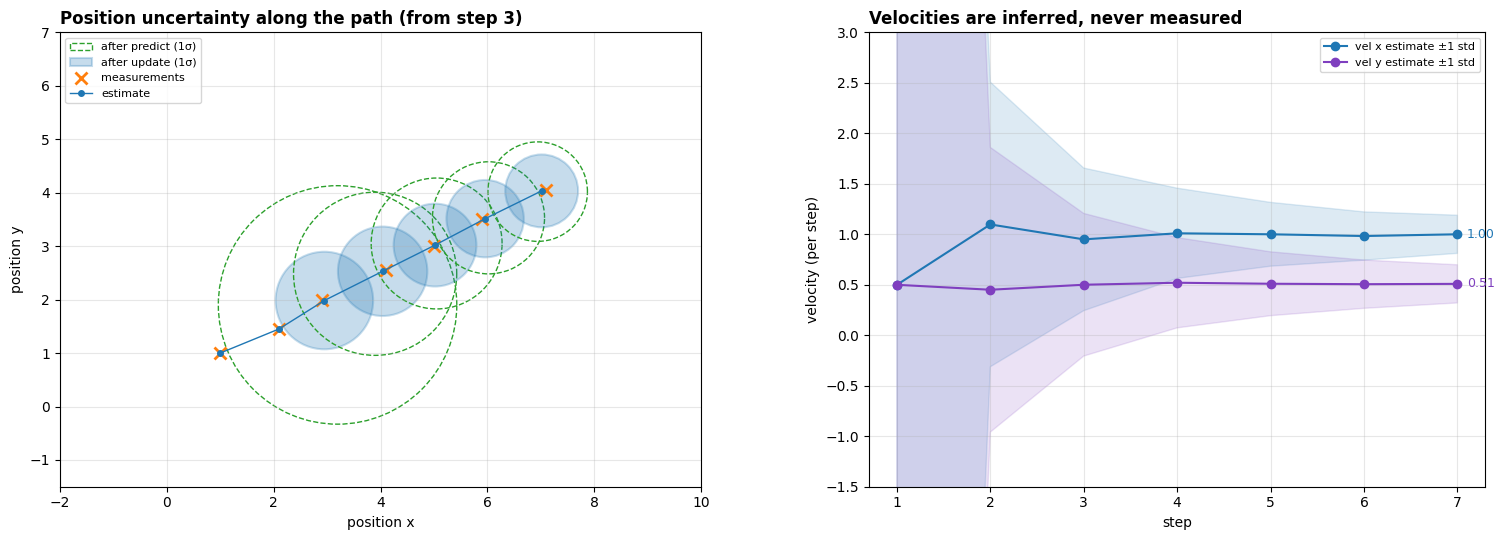

In [75]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})

ax = axs[0]
for i, ((mpr, cpr), (mpo, cpo)) in enumerate(zip(priors, posteriors)):
    if i < 2:
        continue          # the first priors have huge variance (started at 1000) and would fill the plot
    cov_ellipse(ax, mpr, cpr, nstd=1, fc="none", ec=C_PRIOR, lw=1, ls="--",
                label="after predict (1σ)" if i == 2 else None)
    cov_ellipse(ax, mpo, cpo, nstd=1, fc=C_POST, alpha=0.25, ec=C_POST, lw=1.5,
                label="after update (1σ)" if i == 2 else None)
path = np.array([p[0] for p in posteriors])
ax.plot(measurements_x, measurements_y, "x", color=C_LIK, ms=9, mew=2, label="measurements")
ax.plot(path[:, 0], path[:, 1], "o-", color=C_POST, ms=4, lw=1, label="estimate")
ax.set_xlim(-2, 10); ax.set_ylim(-1.5, 7); ax.set_aspect("equal")
ax.set_xlabel("position x"); ax.set_ylabel("position y"); ax.grid(alpha=0.3)
ax.set_title("Position uncertainty along the path (from step 3)", loc="left", fontweight="bold")
ax.legend(fontsize=8, loc="upper left")

# Re-run to record the velocities (the earlier loop only kept the position part)
xk, Pk = np.zeros((4, 1)), np.eye(4) * 1000.
vx, vy, vx_sd, vy_sd = [], [], [], []
for zx, zy in zip(measurements_x, measurements_y):
    xk, Pk = predict(xk, Pk, F, np.zeros((4, 1)))
    xk, Pk = update(xk, Pk, np.array([[zx], [zy]]), H, R, I)
    vx.append(xk[1, 0]); vy.append(xk[3, 0])
    vx_sd.append(np.sqrt(Pk[1, 1])); vy_sd.append(np.sqrt(Pk[3, 3]))
vx, vy, vx_sd, vy_sd = map(np.array, (vx, vy, vx_sd, vy_sd))
st = np.arange(1, len(vx) + 1)

ax = axs[1]
for v, sd, c, name in [(vx, vx_sd, C_POST, "vel x"), (vy, vy_sd, "#7f3fbf", "vel y")]:
    ax.fill_between(st, v - sd, v + sd, color=c, alpha=0.15)
    ax.plot(st, v, "o-", color=c, label=f"{name} estimate ±1 std")
    ax.text(st[-1] + 0.1, v[-1], f"{v[-1]:.2f}", color=c, va="center", fontsize=9)
ax.set_ylim(-1.5, 3)
ax.set_xlabel("step"); ax.set_ylabel("velocity (per step)")
ax.set_title("Velocities are inferred, never measured", loc="left", fontweight="bold")
ax.legend(fontsize=8, loc="upper right"); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()